# Can the ω_m(ℓ) model see beyond-ΛCDM physics in the mock?

For each mock, the same data fitted twice:
- **fixed ω_m** (`one_bin.param`, plain ΛCDM): one ω_m for all ℓ → a flat band;
- **ℓ-dependent ω_m** (`poly.param`): ω_m(ℓ) = ω_m0 + b x + c x², x = (ℓ − ℓ_c)/1000.

If the ℓ-dependent band bends away from the flat one, the model sees something ΛCDM can't fit.
One figure per mock: mAxiCLASS (EDE) mock, then ΛCDM mock (null test: should stay flat).
Run from the `omega_m/` root.

In [5]:
from pathlib import Path
import re, ast, glob
import numpy as np
import matplotlib.pyplot as plt
from getdist import loadMCSamples

CH = Path("with_cp_lcdm/chains")
MOCKS = {   # title: (mock file, fixed-omega_m chains, l-dependent chains)
    "mAxiCLASS EDE mock": (Path("with_maxiclass/model/ede2ax_pdh0_mean.dat"),
                           CH / "model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin",
                           CH / "model_ede1ax_f012_z1e4_from_maxiclass__param_poly"),
    r"$\Lambda$CDM mock (CLASS)": (Path("with_class_mnu/model/lcdm.dat"),
                           CH / "model_lcdm_from_class_mnu__param_one_bin",
                           CH / "model_lcdm_from_class_mnu__param_poly"),
}
BURN_IN = 0.3
ELL = np.linspace(2, 2508, 300)

def load(folder):
    """GetDist samples of the run with most chain files in the folder, plus its log.param values."""
    text = (folder / "log.param").read_text()
    logp = {n: ast.literal_eval(r) for n, r in
            re.findall(r"^data\.parameters\[['\"](.+?)['\"]\]\s*=\s*(\[.*?\])", text, re.M)}
    roots = {}
    for f in folder.glob("*.paramnames"):
        root = str(f)[:-len(".paramnames")]
        n = [c for c in glob.glob(glob.escape(root) + "_[0-9]*.txt") if Path(c).stat().st_size > 0]
        if n:
            roots[root] = len(n)
    s = loadMCSamples(max(roots, key=roots.get), settings={"ignore_rows": BURN_IN}, no_cache=True)
    return s, logp

def omega_m_band(s, logp):
    """68% and 95% bands + median of omega_m(l); flat for a fixed-omega_m run."""
    om0 = s.samples[:, s.index["omega_m0"]]
    d = np.zeros((len(om0), 1))
    if "l_c" in logp:
        x = (ELL - logp["l_c"][0]) / (logp["l_norm"][0] if "l_norm" in logp else 1000.0)
        for k, name in enumerate(["dwm_a", "dwm_b", "dwm_c"]):
            if name in s.index:
                d = d + np.outer(s.samples[:, s.index[name]], x ** k)
            elif name in logp:
                d = d + logp[name][0] * x ** k
    om = om0[:, None] + d * np.ones(len(ELL))
    w = s.weights
    out = []
    for j in range(len(ELL)):
        i = np.argsort(om[:, j]); cw = np.cumsum(w[i]) / w.sum()
        out.append(np.interp([0.025, 0.16, 0.5, 0.84, 0.975], cw, om[i, j]))
    return np.array(out).T

def chi2_min(folder):
    root = max(glob.glob(str(folder / "*_[0-9]*.txt")), key=lambda f: 0)  # any chain file -> its root
    root = re.sub(r"_\d+\.txt$", "", root)
    return 2 * min(np.loadtxt(f, ndmin=2)[:, 1].min() for f in glob.glob(glob.escape(root) + "_[0-9]*.txt")
                   if Path(f).stat().st_size > 0)

with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__1.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__2.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__3.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__4.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__5.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__6.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__7.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_one_bin/2026-10-23_100000__8.txt
Removed 0.3 as burn in
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__1.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__2.txt
wit

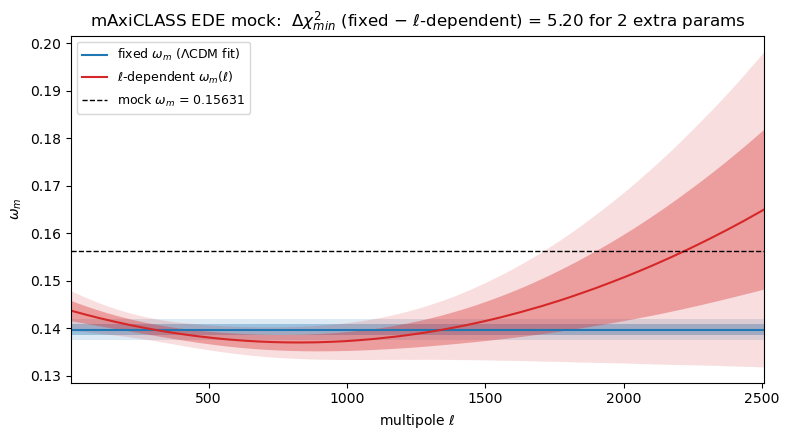

with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__1.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__2.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__3.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__4.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__5.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__6.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__7.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_one_bin/2026-10-16_100000__8.txt
Removed 0.3 as burn in
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_poly/2026-10-20_100000__1.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_poly/2026-10-20_100000__2.txt
with_cp_lcdm/chains/model_lcdm_from_class_mnu__param_poly/2026-10-20_100000__3.txt
with_cp_lcdm/chains/model_lcdm_from_clas

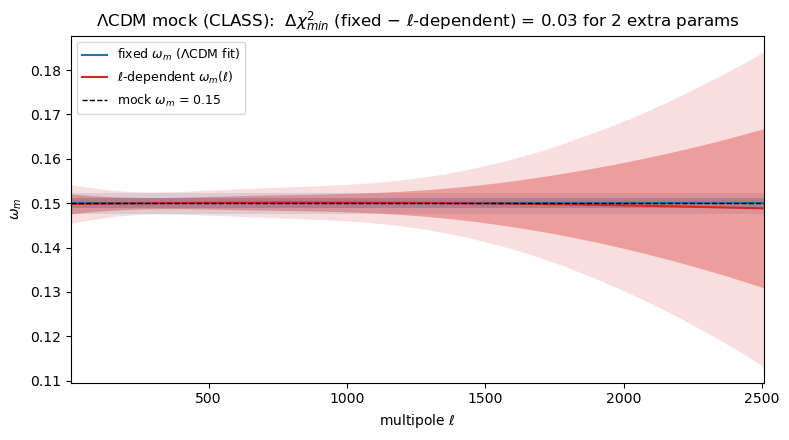

In [6]:
for title, (mock, fixed_dir, poly_dir) in MOCKS.items():
    header = mock.open().readline()
    om_true = float(re.search(r"omega_m0\s*=\s*([\d.]+)", header).group(1))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for folder, label, col in [(fixed_dir, r"fixed $\omega_m$ ($\Lambda$CDM fit)", "C0"),
                               (poly_dir, r"$\ell$-dependent $\omega_m(\ell)$", "C3")]:
        b = omega_m_band(*load(folder))
        ax.fill_between(ELL, b[0], b[4], color=col, alpha=0.15, lw=0)
        ax.fill_between(ELL, b[1], b[3], color=col, alpha=0.35, lw=0)
        ax.plot(ELL, b[2], color=col, lw=1.5, label=label)
    ax.axhline(om_true, color="k", ls="--", lw=1, label=rf"mock $\omega_m$ = {om_true:g}")
    dchi2 = chi2_min(fixed_dir) - chi2_min(poly_dir)
    ax.set_title(f"{title}:  $\\Delta\\chi^2_{{min}}$ (fixed − $\\ell$-dependent) = {dchi2:.2f} for 2 extra params")
    ax.set_xlabel(r"multipole $\ell$"); ax.set_ylabel(r"$\omega_m$")
    ax.set_xlim(ELL[0], ELL[-1]); ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig("omega_m_of_ell_" + re.sub(r"\W+", "_", title).strip("_") + ".png", dpi=150)
    plt.show()

## Prior bands

Same figure, with the **prior** on ω_m(ℓ) drawn as outlines (solid 68%, dashed 95%) in the colour of each run.
The prior is obtained by drawing the varied ω_m(ℓ) parameters (ω_m0, dwm_b, dwm_c) uniformly within their `log.param` bounds
and passing them through the same `omega_m_band()` as the chains. Since ω_m(ℓ) = ω_m0 + b x + c x² is a sum of uniforms,
this prior is not flat in ω_m(ℓ) and widens away from ℓ_c.

In [7]:
from types import SimpleNamespace
N_PRIOR = 50_000   # om array in omega_m_band is N_PRIOR x len(ELL) floats
rng = np.random.default_rng(0)

def prior_samples(logp):
    """Uniform draws of the varied omega_m(l) parameters within their log.param bounds, shaped like GetDist samples."""
    names = [n for n in ["omega_m0", "dwm_a", "dwm_b", "dwm_c"] if n in logp and logp[n][3] != 0]
    for n in names:
        assert None not in logp[n][1:3], f"{n}: no prior bound in log.param"
    x = np.column_stack([rng.uniform(logp[n][1], logp[n][2], N_PRIOR) for n in names])
    return SimpleNamespace(samples=x, index={n: i for i, n in enumerate(names)}, weights=np.ones(N_PRIOR))

for title, (mock, fixed_dir, poly_dir) in MOCKS.items():
    header = mock.open().readline()
    om_true = float(re.search(r"omega_m0\s*=\s*([\d.]+)", header).group(1))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for folder, label, col in [
                               #(fixed_dir, r"fixed $\omega_m$ ($\Lambda$CDM fit)", "C0"),
                               (poly_dir, r"$\ell$-dependent $\omega_m(\ell)$", "C3")]:
        s, logp = load(folder)
        b = omega_m_band(s, logp)
        ax.fill_between(ELL, b[0], b[4], color=col, alpha=0.15, lw=0)
        ax.fill_between(ELL, b[1], b[3], color=col, alpha=0.35, lw=0)
        ax.plot(ELL, b[2], color=col, lw=1.5, label=label)
        p = omega_m_band(prior_samples(logp), logp)
        for k, ls in [(0, "--"), (4, "--"), (1, "-"), (3, "-")]:
            ax.plot(ELL, p[k], color=col, ls=ls, lw=0.9)
    ax.axhline(om_true, color="k", ls="--", lw=1, label=rf"mock $\omega_m$ = {om_true:g}")
    ax.plot([], [], color="grey", ls="-", lw=0.9, label="prior 68%")
    ax.plot([], [], color="grey", ls="--", lw=0.9, label="prior 95%")
    dchi2 = chi2_min(fixed_dir) - chi2_min(poly_dir)
    ax.set_title(f"{title}:  $\\Delta\\chi^2_{{min}}$ (fixed − $\\ell$-dependent) = {dchi2:.2f} for 2 extra params")
    ax.set_xlabel(r"multipole $\ell$"); ax.set_ylabel(r"$\omega_m$")
    ax.set_xlim(ELL[0], ELL[-1]); ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig("omega_m_of_ell_" + re.sub(r"\W+", "_", title).strip("_") + "_with_prior.png", dpi=150)
    plt.show()

with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__1.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__2.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__3.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__4.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__5.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__6.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__7.txt
with_cp_lcdm/chains/model_ede1ax_f012_z1e4_from_maxiclass__param_poly/2026-10-23_100000__8.txt
Removed 0.3 as burn in
